In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from IPython.display import display

from models import EASE, FactorizationMachine, IALS, IALSCustomTarget, ItemKNN, Popular
from models.base import get_device, set_seed
from models.fm import ALL_FIELDS, ITEM_CONTEXT_FIELDS, ITEM_FIELDS, USER_CONTEXT_FIELDS, USER_FIELDS
from models.ials_custom import custom_target
from utils.data import clean_interactions, download_raw, encode, k_core, load_cached, make_split
from utils.evaluation import bootstrap_ci, fit_evaluate, paired_bootstrap_diff
from utils.tuning import trials_frame, tune

SEED = 42
K = 10
MAIN_METRIC = "ndcg"
POSITIVE_THRESHOLD = 4
CORE_K = 5
VAL_START, TEST_START = "2022-04-01", "2022-10-01"
N_TRIALS = {"Popular": 8, "ItemKNN": 30, "EASE": 15, "iALS": 30, "iALS-custom": 40, "FM": 25}
DATA_DIR = Path("data")
RAW_DIR, CACHE_DIR = DATA_DIR / "raw", DATA_DIR / "cache"
DEVICE = get_device()

set_seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
NOTEBOOK_START = time.perf_counter()
print("device:", DEVICE, "| torch", torch.__version__, "| optuna", optuna.__version__,
      "|", torch.cuda.get_device_name() if DEVICE.type == "cuda" else "cpu")

/home/adaniyarov/ysda_recsys_hw1/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda | torch 2.14.1+cu126 | optuna 5.0.0 | NVIDIA A100 80GB PCIe


## 1. Загрузка и описание данных

Amazon Reviews 2023, категория Video_Games (https://amazon-reviews-2023.github.io/). Взаимодействие: отзыв на товар, считаю его покупкой; у отзыва есть оценка 1-5 и время. Релевантным считаю отзыв в тестовом периоде с оценкой от 4. Исходно 4.6 млн отзывов, после очистки 814 586 взаимодействий, 94 762 пользователя и 25 612 товаров.

In [2]:
t0 = time.perf_counter()
download_raw(RAW_DIR)
reviews, meta = load_cached(RAW_DIR, CACHE_DIR)
print(f"загрузка: {time.perf_counter() - t0:.0f} c")

dates = pd.to_datetime(reviews.timestamp, unit="ms")
display(pd.Series({
    "отзывов": f"{len(reviews):,}",
    "пользователей": f"{reviews.user_id.nunique():,}",
    "товаров с отзывами": f"{reviews.item_id.nunique():,}",
    "товаров в метаданных": f"{len(meta):,}",
    "период": f"{dates.min():%Y-%m-%d} — {dates.max():%Y-%m-%d}",
    "доля verified_purchase": f"{reviews.verified_purchase.mean():.3f}",
}, name="сырые данные Video_Games").to_frame())
display(reviews.head(3))
display(meta.head(3))

загрузка: 2 c


,сырые данные Video_Games
отзывов,"4,624,615"
пользователей,"2,766,656"
товаров с отзывами,"137,249"
товаров в метаданных,"137,269"
период,1998-11-17 — 2023-09-12
доля verified_purchase,0.861


,user_id,item_id,rating,timestamp,helpful_vote,verified_purchase,text_len
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07DK1H3H5,4.0000,1608186804795,0,True,226
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07SRWRH5D,5.0000,1587051114941,1,False,85
2,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,B07MFMFW34,5.0000,1490877431000,0,True,78


,item_id,title,main_category,store,categories,price,rated,date_first_available,release_date,n_features,description_len,average_rating,rating_number
0,B000FH0MHO,Dash 8-300 Professional Add-On,Video Games,Aerosoft,"[Video Games, PC, Games]",NaN,Everyone,2001-10-02,NaT,4,507,5.0000,1
1,B00069EVOG,Phantasmagoria: A Puzzle of Flesh,Video Games,Sierra,"[Video Games, PC, Games]",NaN,Mature,2006-03-30,NaT,1,0,4.1000,18
2,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,2K,"[Video Games, PlayStation 4, Games]",58.0000,Everyone,2016-04-13,2016-09-16,10,341,4.3000,223


## 2. EDA и подготовка данных

### 2.1 Пропуски и дубликаты

In [3]:
def filled_share(s: pd.Series) -> float:
    def ok(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return False
        if isinstance(v, (str, list, np.ndarray)):
            return len(v) > 0
        return not pd.isna(v)
    return s.map(ok).mean()

display(reviews.isna().sum().rename("пропусков в отзывах").to_frame().T)
meta_cols = ["title", "main_category", "store", "categories", "price", "rated", "date_first_available", "release_date"]
meta_coverage = pd.DataFrame({
    "все товары метаданных": [filled_share(meta[c]) for c in meta_cols],
    "товары с отзывами": [filled_share(meta.loc[meta.item_id.isin(reviews.item_id), c]) for c in meta_cols],
}, index=meta_cols)
display(meta_coverage.style.format("{:.1%}").set_caption("Доля заполненных полей метаданных"))
print("товаров с отзывами, но без метаданных:", len(set(reviews.item_id) - set(meta.item_id)))

,user_id,item_id,rating,timestamp,helpful_vote,verified_purchase,text_len
пропусков в отзывах,0,0,0,0,0,0,0


,все товары метаданных,товары с отзывами
title,100.0%,100.0%
main_category,92.0%,92.0%
store,96.8%,96.8%
categories,90.8%,90.8%
price,45.1%,45.1%
rated,30.2%,30.2%
date_first_available,93.6%,93.6%
release_date,25.5%,25.6%


товаров с отзывами, но без метаданных: 0


In [4]:
full_dups = reviews.duplicated().sum()
pair_dups = reviews.duplicated(["user_id", "item_id"]).sum()
multi = reviews[reviews.duplicated(["user_id", "item_id"], keep=False)].drop_duplicates()
gaps = multi.groupby(["user_id", "item_id"]).timestamp.agg(lambda s: (s.max() - s.min()) / 86_400_000)
print(f"полных дубликатов строк: {full_dups:,}")
print(f"повторных пар (user, item) сверх первой: {pair_dups:,} ({pair_dups / len(reviews):.2%} отзывов)")
print(f"пар с несколькими различающимися отзывами: {len(gaps):,}; медианный разрыв между ними: {gaps.median():.0f} дн.; "
      f"доля пар с одинаковой датой: {(gaps == 0).mean():.1%}")

полных дубликатов строк: 53,650
повторных пар (user, item) сверх первой: 69,115 (1.49% отзывов)
пар с несколькими различающимися отзывами: 57,967; медианный разрыв между ними: 0 дн.; доля пар с одинаковой датой: 77.7%


Пропусков нет. Полные дубликаты удалил, а из повторных пар user-item оставил первый отзыв.

### 2.2 Распределения в сырых данных

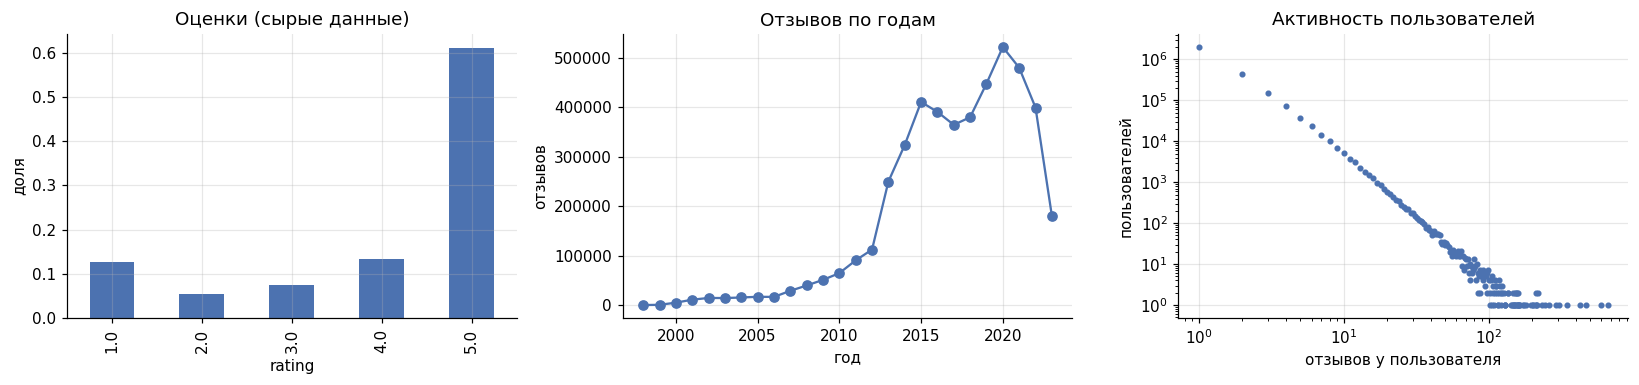

доля пользователей с одним отзывом: 72.2%; с >= 5 отзывами: 4.3%


In [5]:
user_cnt_raw = reviews.user_id.value_counts()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
reviews.rating.value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Оценки (сырые данные)", xlabel="rating", ylabel="доля")
dates.dt.year.value_counts().sort_index().plot(ax=ax[1], marker="o", color="#4C72B0")
ax[1].set(title="Отзывов по годам", xlabel="год", ylabel="отзывов")
vc = user_cnt_raw.value_counts().sort_index()
ax[2].loglog(vc.index, vc.values, ".", color="#4C72B0")
ax[2].set(title="Активность пользователей", xlabel="отзывов у пользователя", ylabel="пользователей")
plt.tight_layout(); plt.show()
print(f"доля пользователей с одним отзывом: {(user_cnt_raw == 1).mean():.1%}; с >= 5 отзывами: {(user_cnt_raw >= 5).mean():.1%}")

### 2.3 Очистка и формирование подвыборки

In [6]:
def describe(df: pd.DataFrame) -> dict:
    n_u, n_i = df.user_id.nunique(), df.item_id.nunique()
    return {"взаимодействий": len(df), "пользователей": n_u, "товаров": n_i, "плотность": len(df) / (n_u * n_i)}

steps = {"сырые отзывы": describe(reviews)}
step = reviews.drop_duplicates();                                                   steps["без полных дубликатов"] = describe(step)
step = step.sort_values(["timestamp", "user_id", "item_id"], kind="stable").drop_duplicates(["user_id", "item_id"])
steps["первый отзыв в паре (user, item)"] = describe(step)
step = step[step.item_id.isin(set(meta.item_id))];                                  steps["товары с метаданными"] = describe(step)
step = k_core(step, CORE_K);                                                        steps[f"итеративный {CORE_K}-core"] = describe(step)
display(pd.DataFrame(steps).T.style.format({"взаимодействий": "{:,.0f}", "пользователей": "{:,.0f}", "товаров": "{:,.0f}", "плотность": "{:.2e}"}))

clean = clean_interactions(reviews, meta, k=CORE_K)
assert len(clean) == len(step)
data = encode(clean, meta)
inter = data.interactions
print(f"итог: {len(inter):,} взаимодействий, {data.n_users:,} пользователей, {data.n_items:,} товаров")

,взаимодействий,пользователей,товаров,плотность
сырые отзывы,"4,624,615","2,766,656","137,249",1.22e-05
без полных дубликатов,"4,570,965","2,766,656","137,249",1.20e-05
"первый отзыв в паре (user, item)","4,555,500","2,766,656","137,249",1.20e-05
товары с метаданными,"4,555,500","2,766,656","137,249",1.20e-05
итеративный 5-core,"814,586","94,762","25,612",3.36e-04


итог: 814,586 взаимодействий, 94,762 пользователей, 25,612 товаров


Оставил только пользователей и товары, у которых минимум 5 отзывов.

### 2.4 Данные после очистки

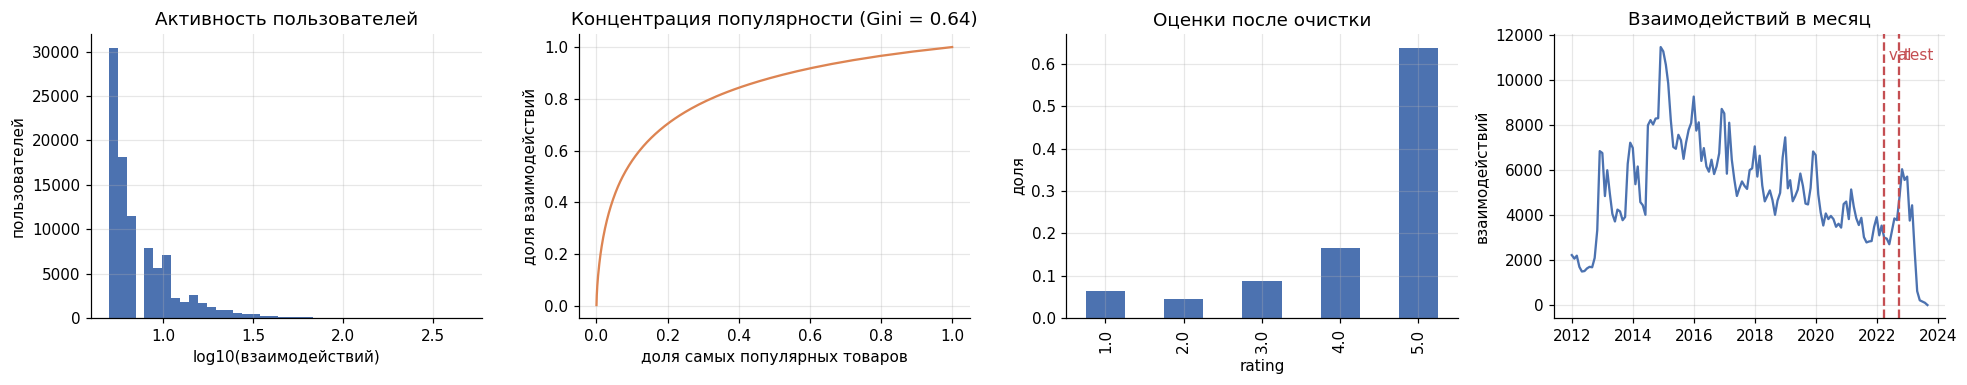

,значение
медиана взаимодействий на пользователя,6.0000
среднее взаимодействий на пользователя,8.5961
медиана взаимодействий на товар,12.0000
доля взаимодействий у топ-1% товаров,0.1859
доля взаимодействий у топ-20% товаров,0.7036
доля оценок >= 4,0.8039
разреженность (1 - плотность),0.9997


In [7]:
user_cnt = inter.user_idx.value_counts()
item_cnt = inter.item_idx.value_counts()
sorted_items = np.sort(item_cnt.to_numpy())[::-1]
lorenz = np.cumsum(sorted_items) / sorted_items.sum()
gini = 1 - 2 * np.trapezoid(np.cumsum(np.sort(item_cnt.to_numpy())) / item_cnt.sum(), dx=1 / len(item_cnt))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].hist(np.log10(user_cnt), bins=40, color="#4C72B0")
ax[0].set(title="Активность пользователей", xlabel="log10(взаимодействий)", ylabel="пользователей")
ax[1].plot(np.arange(1, len(lorenz) + 1) / len(lorenz), lorenz, color="#DD8452")
ax[1].set(title=f"Концентрация популярности (Gini = {gini:.2f})", xlabel="доля самых популярных товаров", ylabel="доля взаимодействий")
inter.rating.value_counts(normalize=True).sort_index().plot.bar(ax=ax[2], color="#4C72B0")
ax[2].set(title="Оценки после очистки", xlabel="rating", ylabel="доля")
monthly = inter.groupby(pd.to_datetime(inter.ts, unit="s").dt.to_period("M")).size()
monthly = monthly[monthly.index >= "2012-01"]
ax[3].plot(monthly.index.to_timestamp(), monthly.values, color="#4C72B0")
for d, lbl in ((VAL_START, "val"), (TEST_START, "test")):
    ax[3].axvline(pd.Timestamp(d), color="#C44E52", ls="--"); ax[3].text(pd.Timestamp(d), monthly.max() * 0.95, f" {lbl}", color="#C44E52")
ax[3].set(title="Взаимодействий в месяц", ylabel="взаимодействий")
plt.tight_layout(); plt.show()

display(pd.Series({
    "медиана взаимодействий на пользователя": user_cnt.median(),
    "среднее взаимодействий на пользователя": user_cnt.mean(),
    "медиана взаимодействий на товар": item_cnt.median(),
    "доля взаимодействий у топ-1% товаров": lorenz[int(0.01 * len(lorenz)) - 1],
    "доля взаимодействий у топ-20% товаров": lorenz[int(0.2 * len(lorenz)) - 1],
    "доля оценок >= 4": (inter.rating >= POSITIVE_THRESHOLD).mean(),
    "разреженность (1 - плотность)": 1 - len(inter) / (data.n_users * data.n_items),
}).to_frame("значение"))

Матрица очень разреженная.

### 2.5 Метаданные

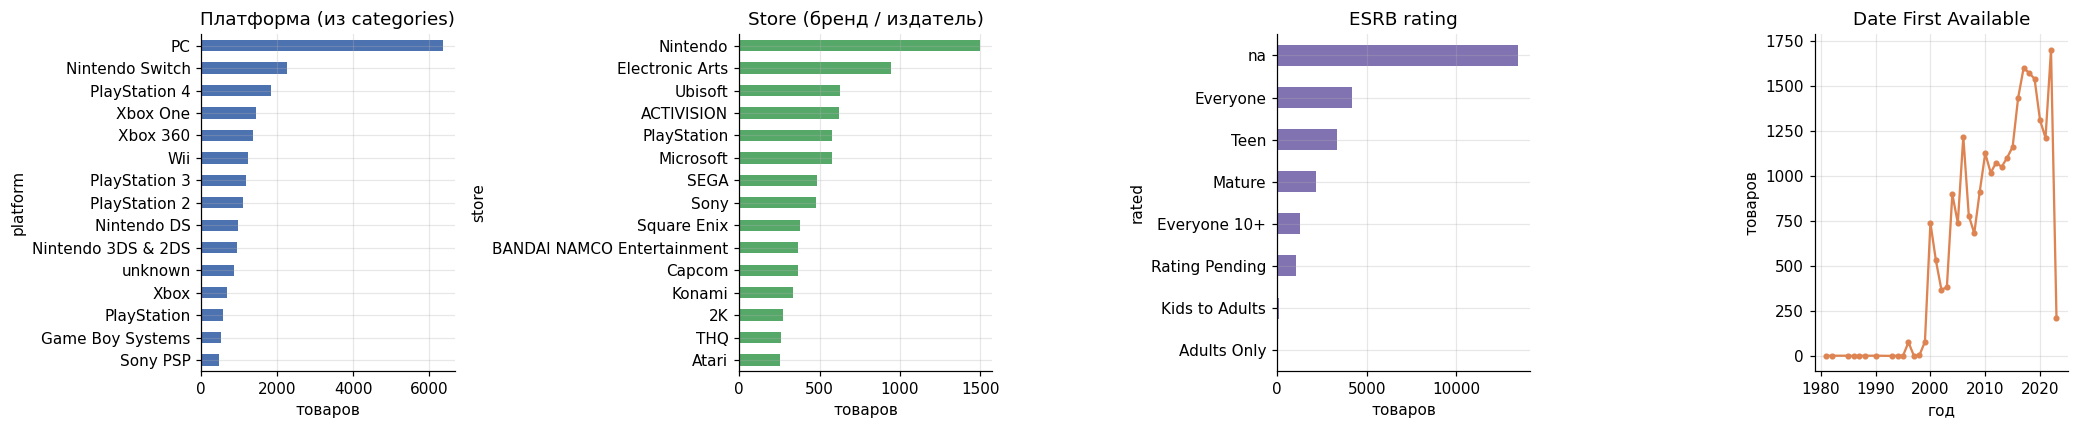

типов товара (последний уровень пути): {'Games': 11450, 'Accessories': 2350, 'Headsets': 1450, 'Cases & Storage': 946, 'unknown': 869, 'Gaming Keyboards': 850}
уникальных store: 3905 | уникальных путей категорий: 441
частые токены названий: ['for', 'with', 'nintendo', 'xbox', 'switch', 'controller', '2', 'gaming', 'playstation', 'pc', 'and', 'one', 'the', 'game', '4', '3', 'case', 'black', 'of', 'ps4', 's', 'wireless', 'edition', 'compatible', 'usb']


In [8]:
im = data.item_meta

def platform(cats) -> str:
    cats = list(cats)
    if len(cats) < 2:
        return "unknown"
    if cats[1] == "Legacy Systems":
        return cats[3] if len(cats) >= 4 else cats[2] if len(cats) >= 3 else "Legacy"
    return cats[1]

im = im.assign(platform=im.categories.map(platform), kind=im.categories.map(lambda c: list(c)[-1] if len(c) else "unknown"))
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
im.platform.value_counts().head(15)[::-1].plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set(title="Платформа (из categories)", xlabel="товаров")
im.store.value_counts().head(15)[::-1].plot.barh(ax=ax[1], color="#55A868"); ax[1].set(title="Store (бренд / издатель)", xlabel="товаров")
im.rated.fillna("na").value_counts().head(8)[::-1].plot.barh(ax=ax[2], color="#8172B2"); ax[2].set(title="ESRB rating", xlabel="товаров")
im.date_first_available.dt.year.value_counts().sort_index().plot(ax=ax[3], marker=".", color="#DD8452")
ax[3].set(title="Date First Available", xlabel="год", ylabel="товаров")
plt.tight_layout(); plt.show()

print("типов товара (последний уровень пути):", im.kind.value_counts().head(6).to_dict())
print("уникальных store:", im.store.nunique(), "| уникальных путей категорий:", im.categories.map(tuple).nunique())
title_tokens = im.title.fillna("").str.lower().str.findall(r"[a-z0-9]+").explode()
print("частые токены названий:", title_tokens.value_counts().head(25).index.tolist())

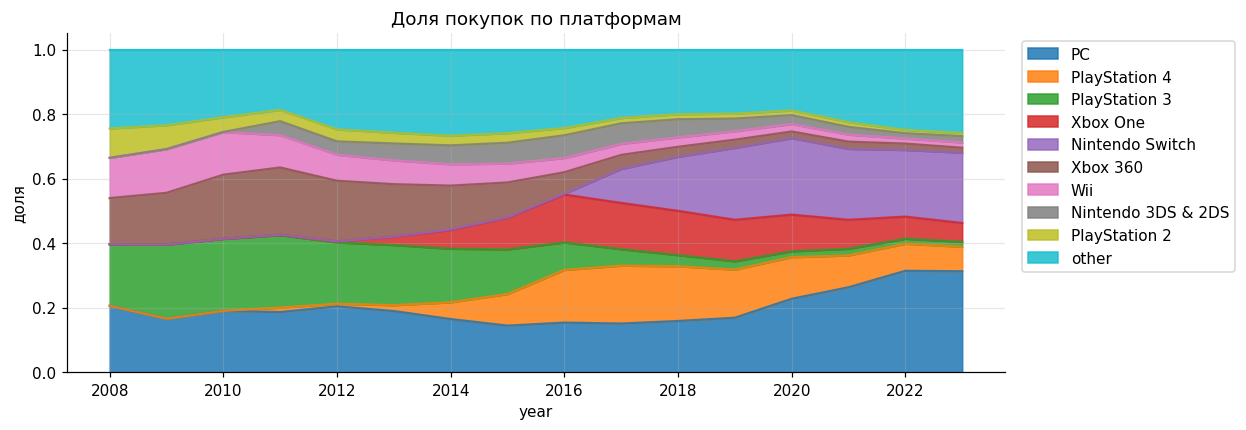

доля покупок в первые 90 дней после появления товара: 5.9%, в первый год: 27.9%


In [9]:
inter_pf = inter.assign(year=pd.to_datetime(inter.ts, unit="s").dt.year, platform=im.platform.to_numpy()[inter.item_idx])
top_pf = inter_pf.platform.value_counts().head(9).index
share = (inter_pf[inter_pf.year.between(2008, 2023)]
         .assign(platform=lambda d: d.platform.where(d.platform.isin(top_pf), "other"))
         .pipe(lambda d: pd.crosstab(d.year, d.platform, normalize="index")))
share[list(top_pf) + ["other"]].plot.area(figsize=(11, 4), cmap="tab10", alpha=0.85)
plt.title("Доля покупок по платформам"); plt.ylabel("доля"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()

age_at_purchase = (pd.to_datetime(inter.ts, unit="s") - im.date_first_available.to_numpy()[inter.item_idx]).dt.days
print(f"доля покупок в первые 90 дней после появления товара: {(age_at_purchase.between(0, 90)).mean():.1%}, "
      f"в первый год: {(age_at_purchase.between(0, 365)).mean():.1%}")

Из метаданных беру категории, store, название, ESRB и дату появления товара. Цену и средний рейтинг не беру, так как это значения на 2023 год.

## 3. Протокол оценки

Разбиение по времени: train до 2022-04-01, val до 2022-10-01, дальше test. На val подбираю гиперпараметры, на test считаю итоговые метрики. Основная метрика NDCG@10, дополнительная Recall@10.

In [10]:
val_split = make_split(data, "validation", VAL_START, TEST_START, POSITIVE_THRESHOLD)
test_split = make_split(data, "test", TEST_START, None, POSITIVE_THRESHOLD)
display(pd.DataFrame({s.name: s.summary() for s in (val_split, test_split)}))
assert val_split.history.multiply(val_split.relevant).nnz == 0 and test_split.history.multiply(test_split.relevant).nnz == 0

,validation,test
взаимодействий в обучении,761295.0000,780826.0000
пользователей в обучении,92593.0000,93413.0000
товаров-кандидатов,23757.0000,24488.0000
взаимодействий в окне,19531.0000,33760.0000
пользователей в окне,9490.0000,11125.0000
доля событий окна с новым пользователем,0.1830,0.3020
доля событий окна с новым товаром,0.2150,0.3950
оцениваемых пользователей,5867.0000,6546.0000
релевантных пар,9736.0000,11939.0000
релевантных на пользователя,1.6600,1.8200


## 4. Модели: постановка и формулы

### 4.0 Popular (baseline)

Число покупок за последние $W$ дней.

### 4.1 Item-based kNN (`models/item_knn.py`)

$\mathrm{sim}(j,i) = \frac{\sum_u x_{uj} x_{ui}}{n_j^{\alpha} n_i^{1-\alpha} + \lambda}$, $\quad s(u,i) = \sum_{j \in I_u} 2^{-\Delta t_{uj}/h}\,\mathrm{sim}(j,i)$

### 4.2 iALS (`models/ials.py`)

$\min \sum_{u,i} c_{ui}(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2)$, для покупок $p_{ui} = 1$, $c_{ui} = 1 + \alpha$.

### 4.3 EASE (`models/ease.py`)

$P = (X^\top X + \lambda I)^{-1}$, $\quad B = -P / \mathrm{diag}(P)$, $\quad \mathrm{diag}(B) = 0$

### 4.4 Factorization Machine с метапризнаками (`models/fm.py`)

$\hat y = w_0 + \sum_j w_j x_j + \sum_{j<l} \langle v_j, v_l \rangle x_j x_l$, BPR. Признаки: профиль пользователя по категориям и store, атрибуты товара, возраст и популярность товара на момент покупки, активность пользователя. Всё по данным до момента покупки.

### 4.5 iALS с собственным целевым сигналом (`models/ials_custom.py`)

Как iALS, но $p_{ui} = \left(1 + \beta\,\frac{r_{ui} - \bar r_u}{4}\right)\left(\gamma + (1-\gamma)\,2^{-\Delta t_{ui}/h}\right)$, $\beta \in [0, 1]$. Первый множитель: оценка относительно средней у пользователя, второй: давность покупки.

## 5. Подбор гиперпараметров на validation

Optuna (TPE, seed 42), подбор по NDCG@10 на val. Пространства поиска заданы в функциях `suggest_*`.

In [11]:
def suggest_popular(trial):
    return {"window_days": trial.suggest_categorical("window_days", [7, 14, 30, 60, 90, 180, 365, None])}

def make_popular(p):
    return Popular(window_days=p["window_days"], device=DEVICE)

def suggest_knn(trial):
    p = {"k": trial.suggest_int("k", 10, 1000, log=True),
         "shrink": trial.suggest_float("shrink", 0.0, 100.0),
         "alpha": trial.suggest_float("alpha", 0.1, 0.9),
         "iuf": trial.suggest_categorical("iuf", [False, True]),
         "time_decay": trial.suggest_categorical("time_decay", [False, True])}
    if p["time_decay"]:
        p["half_life_days"] = trial.suggest_float("half_life_days", 30, 3650, log=True)
    return p

def make_knn(p):
    return ItemKNN(k=p["k"], shrink=p["shrink"], alpha=p["alpha"], iuf=p["iuf"],
                   half_life_days=p["half_life_days"] if p["time_decay"] else None, device=DEVICE)

def suggest_ease(trial):
    return {"reg": trial.suggest_float("reg", 1.0, 1e4, log=True)}

def make_ease(p):
    return EASE(reg=p["reg"], device=DEVICE)

def suggest_ials(trial):
    return {"factors": trial.suggest_categorical("factors", [64, 128, 256, 512]),
            "reg": trial.suggest_float("reg", 1.0, 3000.0, log=True),
            "alpha": trial.suggest_float("alpha", 1.0, 500.0, log=True)}

def make_ials(p):
    return IALS(factors=p["factors"], reg=p["reg"], alpha=p["alpha"], iterations=15, cg_steps=3, seed=SEED, device=DEVICE)

def suggest_custom(trial):
    p = suggest_ials(trial)
    p.update(beta=trial.suggest_float("beta", 0.0, 1.0),
             half_life_days=trial.suggest_float("half_life_days", 30, 3650, log=True),
             floor=trial.suggest_float("floor", 0.0, 1.0))
    return p

def make_custom(p):
    return IALSCustomTarget(beta=p["beta"], half_life_days=p["half_life_days"], floor=p["floor"],
                            factors=p["factors"], reg=p["reg"], alpha=p["alpha"], iterations=15, cg_steps=3, seed=SEED, device=DEVICE)

def suggest_fm(trial):
    return {"factors": trial.suggest_categorical("factors", [32, 64, 128]),
            "lr": trial.suggest_float("lr", 5e-4, 1e-2, log=True),
            "reg": trial.suggest_float("reg", 1e-5, 1e-1, log=True),
            "epochs": trial.suggest_int("epochs", 2, 15),
            "n_neg": trial.suggest_categorical("n_neg", [4, 8, 16]),
            "use_user_id": trial.suggest_categorical("use_user_id", [True, False]),
            "use_item_id": trial.suggest_categorical("use_item_id", [True, False])}

def fm_fields(p):
    drop = {f for f, key in (("user_id", "use_user_id"), ("item_id", "use_item_id")) if not p.get(key, True)}
    return tuple(f for f in ALL_FIELDS if f not in drop)

def make_fm(p, fields=None):
    return FactorizationMachine(fields=fm_fields(p) if fields is None else fields, factors=p["factors"], lr=p["lr"],
                                reg=p["reg"], epochs=p["epochs"], n_neg=p["n_neg"], batch_size=4096, seed=SEED, device=DEVICE)

MAKERS = {"Popular": make_popular, "ItemKNN": make_knn, "EASE": make_ease, "iALS": make_ials, "iALS-custom": make_custom, "FM": make_fm}
MODEL_ORDER = list(MAKERS)
studies, best_params, tuning_time = {}, {}, {}

def run_tuning(name, suggest, enqueue=None, sampler=None):
    t0 = time.perf_counter()
    study = tune(lambda trial: MAKERS[name](suggest(trial)), val_split, N_TRIALS[name], metric=MAIN_METRIC, k=K,
                 seed=SEED, enqueue=enqueue, sampler=sampler)
    studies[name], best_params[name] = study, study.best_params
    tuning_time[name] = time.perf_counter() - t0
    print(f"{name}: {len(study.trials)} проб за {tuning_time[name]:.0f} c; лучший NDCG@10 на validation = {study.best_value:.4f}")
    print("лучшие гиперпараметры:", study.best_params)
    cols = ["number", "value"] + list(study.best_params) + ["recall", "hitrate", "coverage", "fit_time"]
    display(trials_frame(study)[[c for c in cols if c in trials_frame(study)]].head(5))

In [12]:
run_tuning("Popular", suggest_popular,
           sampler=optuna.samplers.GridSampler({"window_days": [7, 14, 30, 60, 90, 180, 365, None]}, seed=SEED))

Popular: 8 проб за 3 c; лучший NDCG@10 на validation = 0.0246
лучшие гиперпараметры: {'window_days': 90}


,number,value,window_days,recall,hitrate,coverage,fit_time
5,5,0.0246,90.0000,0.0467,0.0682,0.0006,0.0037
4,4,0.0236,30.0000,0.0435,0.0646,0.0006,0.0034
0,0,0.0232,14.0000,0.0473,0.0682,0.0007,0.2587
6,6,0.0225,60.0000,0.0408,0.0598,0.0006,0.0037
2,2,0.0219,7.0000,0.0386,0.0545,0.0007,0.0037


In [13]:
run_tuning("ItemKNN", suggest_knn)

ItemKNN: 30 проб за 55 c; лучший NDCG@10 на validation = 0.0152
лучшие гиперпараметры: {'k': 205, 'shrink': 71.36696502249762, 'alpha': 0.5842828873514246, 'iuf': True, 'time_decay': True, 'half_life_days': 275.0848793327383}


,number,value,k,shrink,alpha,iuf,time_decay,half_life_days,recall,hitrate,coverage,fit_time
27,27,0.0152,205,71.3670,0.5843,True,True,275.0849,0.0268,0.0418,0.3319,0.3269
25,25,0.0152,775,77.4806,0.5799,True,True,244.1160,0.0260,0.0414,0.3033,0.3299
29,29,0.0151,399,77.9986,0.6388,True,True,66.3291,0.0252,0.0401,0.3694,0.3272
23,23,0.0150,367,96.7326,0.7734,True,True,263.9652,0.0261,0.0407,0.2902,0.3285
11,11,0.0150,184,57.8872,0.8992,True,True,342.2008,0.0257,0.0412,0.2969,0.3323


In [14]:
run_tuning("EASE", suggest_ease)

EASE: 15 проб за 106 c; лучший NDCG@10 на validation = 0.0123
лучшие гиперпараметры: {'reg': 29.847990024307485}


,number,value,reg,recall,hitrate,coverage,fit_time
7,7,0.0123,29.8480,0.0199,0.0324,0.2989,5.4460
6,6,0.0123,28.5043,0.0199,0.0322,0.3011,5.5442
0,0,0.0122,31.4891,0.0197,0.0324,0.2966,5.6992
11,11,0.0120,16.5640,0.0196,0.0322,0.3336,5.1687
13,13,0.0118,95.1869,0.0196,0.0326,0.2537,5.1617


In [15]:
run_tuning("iALS", suggest_ials)

iALS: 30 проб за 87 c; лучший NDCG@10 на validation = 0.0150
лучшие гиперпараметры: {'factors': 256, 'reg': 26.556119921952977, 'alpha': 35.65565222304454}


,number,value,factors,reg,alpha,recall,hitrate,coverage,fit_time
22,22,0.0150,256,26.5561,35.6557,0.0241,0.0389,0.1537,1.9411
23,23,0.0147,256,3.1441,42.2350,0.0240,0.0392,0.1718,1.9924
10,10,0.0146,256,1.6282,41.1742,0.0240,0.0392,0.1710,2.0640
25,25,0.0146,256,136.2845,160.3660,0.0253,0.0404,0.1926,2.1139
26,26,0.0145,256,2.6891,47.1388,0.0238,0.0385,0.1769,1.8781


In [16]:
run_tuning("iALS-custom", suggest_custom,
           enqueue=[{**best_params["iALS"], "beta": 0.0, "half_life_days": 365.0, "floor": 1.0}])

iALS-custom: 40 проб за 100 c; лучший NDCG@10 на validation = 0.0233
лучшие гиперпараметры: {'factors': 256, 'reg': 137.58563984128045, 'alpha': 53.590406000298266, 'beta': 0.8395782800018592, 'half_life_days': 625.9578824422006, 'floor': 0.007048323552620972}


,number,value,factors,reg,alpha,beta,half_life_days,floor,recall,hitrate,coverage,fit_time
38,38,0.0233,256,137.5856,53.5904,0.8396,625.9579,0.0070,0.0388,0.0588,0.0801,2.1858
39,39,0.0222,256,109.0692,26.9200,0.9285,433.7881,0.1789,0.0370,0.0568,0.0461,2.0722
35,35,0.0219,256,114.3791,38.9593,0.9567,596.7166,0.1170,0.0368,0.0552,0.0813,2.1637
33,33,0.0207,256,110.7748,44.1451,0.9768,331.3346,0.3427,0.0346,0.0533,0.1131,2.1259
34,34,0.0204,256,90.6169,49.3652,0.9006,824.1867,0.1594,0.0334,0.0508,0.1376,2.1991


In [17]:
run_tuning("FM", suggest_fm)

FM: 25 проб за 3842 c; лучший NDCG@10 на validation = 0.0317
лучшие гиперпараметры: {'factors': 32, 'lr': 0.0029454365745796834, 'reg': 0.0028294605404815777, 'epochs': 8, 'n_neg': 8, 'use_user_id': True, 'use_item_id': False}


,number,value,factors,lr,reg,epochs,n_neg,use_user_id,use_item_id,recall,hitrate,coverage,fit_time
14,14,0.0317,32,0.0029,0.0028,8,8,True,False,0.0573,0.0830,0.0803,125.7184
21,21,0.0311,32,0.0025,0.0023,12,8,True,False,0.0563,0.0827,0.0959,183.9580
22,22,0.0308,32,0.0017,0.0054,11,8,True,False,0.0542,0.0798,0.0446,185.9673
12,12,0.0303,128,0.0015,0.0069,8,8,False,False,0.0525,0.0782,0.0423,164.2642
23,23,0.0302,32,0.0022,0.0059,10,8,True,False,0.0535,0.0803,0.0424,155.3866


,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,проб,"время подбора, c",гиперпараметры
модель,,,,,,,,
Popular,0.0246,0.0467,0.0682,0.0227,0.0006,8,2.7869,{'window_days': 90}
ItemKNN,0.0152,0.0268,0.0418,0.0154,0.3319,30,54.9300,"{'k': 205, 'shrink': 71.36696502249762, 'alpha..."
EASE,0.0123,0.0199,0.0324,0.0133,0.2989,15,105.5971,{'reg': 29.847990024307485}
iALS,0.0150,0.0241,0.0389,0.0158,0.1537,30,86.5666,"{'factors': 256, 'reg': 26.556119921952977, 'a..."
iALS-custom,0.0233,0.0388,0.0588,0.0236,0.0801,40,99.5421,"{'factors': 256, 'reg': 137.58563984128045, 'a..."
FM,0.0317,0.0573,0.0830,0.0303,0.0803,25,3842.1120,"{'factors': 32, 'lr': 0.0029454365745796834, '..."


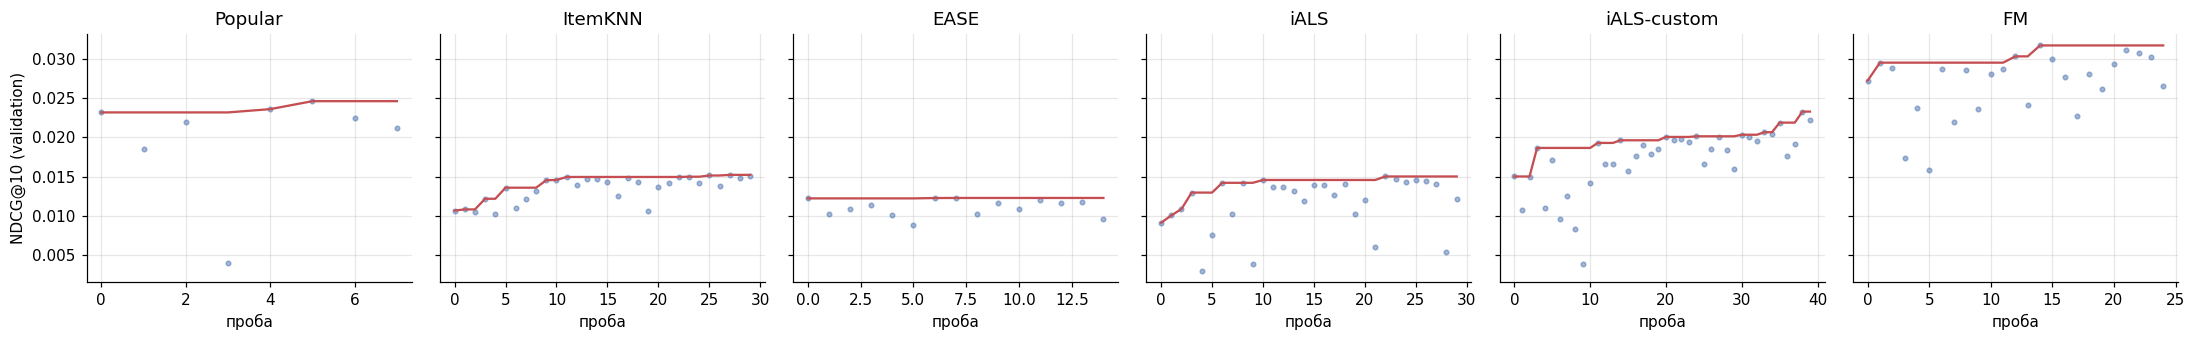

In [18]:
val_rows = []
for name in MODEL_ORDER:
    tr = studies[name].best_trial
    val_rows.append({"модель": name, "NDCG@10": tr.value, "Recall@10": tr.user_attrs["recall"], "HitRate@10": tr.user_attrs["hitrate"],
                     "MRR@10": tr.user_attrs["mrr"], "Coverage@10": tr.user_attrs["coverage"], "проб": len(studies[name].trials),
                     "время подбора, c": tuning_time[name], "гиперпараметры": best_params[name]})
val_table = pd.DataFrame(val_rows).set_index("модель")
display(val_table)

fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(20, 3.2), sharey=True)
for ax, name in zip(axes, MODEL_ORDER):
    values = [t.value for t in studies[name].trials]
    ax.plot(values, ".", alpha=0.5, color="#4C72B0"); ax.plot(np.maximum.accumulate(values), color="#C44E52")
    ax.set(title=name, xlabel="проба")
axes[0].set_ylabel("NDCG@10 (validation)")
plt.tight_layout(); plt.show()

## 6. Финальное сравнение на test

In [19]:
test_results, test_rows = {}, []
for name in MODEL_ORDER:
    model = MAKERS[name](best_params[name])
    res, fit_time = fit_evaluate(model, test_split, K)
    test_results[name] = res
    m = res.metrics
    test_rows.append({"модель": name, "NDCG@10": m["ndcg"], "Recall@10": m["recall"], "HitRate@10": m["hitrate"], "MRR@10": m["mrr"],
                      "Coverage@10": m["coverage"], "ср. популярность рек.": m["mean_rec_popularity"],
                      "NDCG@10 val": studies[name].best_value, "обучение, c": fit_time, "гиперпараметры": best_params[name]})
    del model
test_table = pd.DataFrame(test_rows).set_index("модель")
display(test_table.style.format({c: "{:.4f}" for c in ["NDCG@10", "Recall@10", "HitRate@10", "MRR@10", "Coverage@10", "NDCG@10 val"]}
                                | {"ср. популярность рек.": "{:.0f}", "обучение, c": "{:.1f}"})
        .highlight_max(subset=["NDCG@10", "Recall@10", "HitRate@10", "MRR@10"], color="#c6e5c6"))

,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,ср. популярность рек.,NDCG@10 val,"обучение, c",гиперпараметры
модель,,,,,,,,,
Popular,0.0157,0.0316,0.0515,0.0138,0.0005,255,0.0246,0.0,{'window_days': 90}
ItemKNN,0.0144,0.0250,0.0406,0.0149,0.3661,339,0.0152,0.4,"{'k': 205, 'shrink': 71.36696502249762, 'alpha': 0.5842828873514246, 'iuf': True, 'time_decay': True, 'half_life_days': 275.0848793327383}"
EASE,0.0121,0.0194,0.0347,0.0136,0.3289,458,0.0123,6.9,{'reg': 29.847990024307485}
iALS,0.0124,0.0217,0.0379,0.0134,0.1566,335,0.0150,2.6,"{'factors': 256, 'reg': 26.556119921952977, 'alpha': 35.65565222304454}"
iALS-custom,0.0184,0.0301,0.0503,0.0199,0.0854,361,0.0233,2.9,"{'factors': 256, 'reg': 137.58563984128045, 'alpha': 53.590406000298266, 'beta': 0.8395782800018592, 'half_life_days': 625.9578824422006, 'floor': 0.007048323552620972}"
FM,0.0239,0.0413,0.0637,0.0237,0.0867,151,0.0317,140.7,"{'factors': 32, 'lr': 0.0029454365745796834, 'reg': 0.0028294605404815777, 'epochs': 8, 'n_neg': 8, 'use_user_id': True, 'use_item_id': False}"


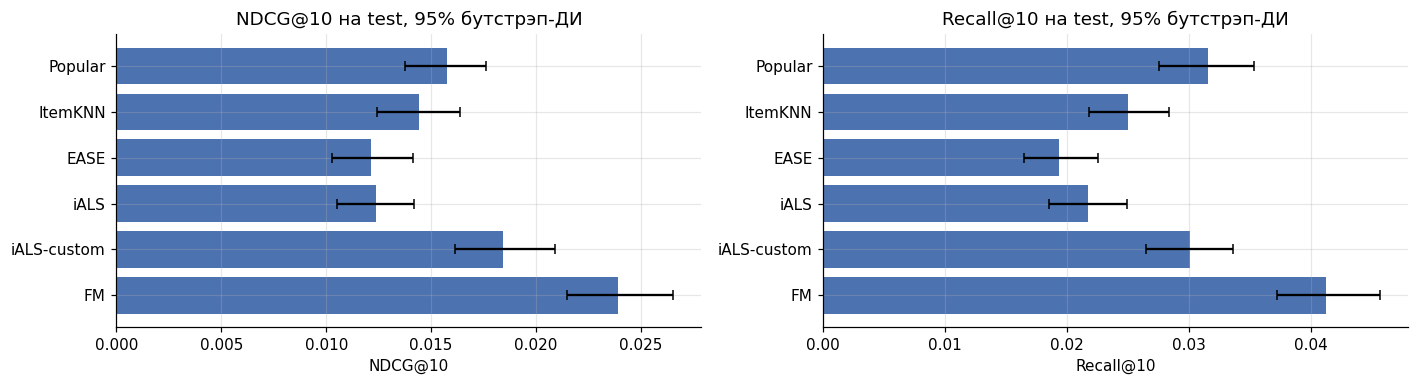

NDCG@10                Recall@10               
               mean ci_low ci_high      mean ci_low ci_high
Popular      0.0157 0.0138  0.0176    0.0316 0.0276  0.0353
ItemKNN      0.0144 0.0124  0.0164    0.0250 0.0218  0.0284
EASE         0.0121 0.0103  0.0141    0.0194 0.0165  0.0226
iALS         0.0124 0.0105  0.0142    0.0217 0.0185  0.0249
iALS-custom  0.0184 0.0161  0.0209    0.0301 0.0265  0.0336
FM           0.0239 0.0215  0.0265    0.0413 0.0373  0.0457

In [20]:
ci = {m: bootstrap_ci({n: test_results[n].per_user[m] for n in MODEL_ORDER}, n_boot=1000, seed=SEED) for m in ("ndcg", "recall")}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, (m, title) in zip(ax, (("ndcg", "NDCG@10"), ("recall", "Recall@10"))):
    c = ci[m].loc[MODEL_ORDER]
    a.barh(c.index, c["mean"], xerr=[c["mean"] - c["ci_low"], c["ci_high"] - c["mean"]], color="#4C72B0", capsize=3)
    a.invert_yaxis(); a.set(title=f"{title} на test, 95% бутстрэп-ДИ", xlabel=title)
plt.tight_layout(); plt.show()
display(pd.concat({"NDCG@10": ci["ndcg"], "Recall@10": ci["recall"]}, axis=1).loc[MODEL_ORDER])

## 7. Анализ

### 7.1 Собственный целевой сигнал против базового iALS

In [21]:
bp = best_params["iALS-custom"]
custom_variants = {
    "базовый iALS (подобранный)": make_ials(best_params["iALS"]),
    "базовый таргет, параметры custom": make_custom({**bp, "beta": 0.0, "floor": 1.0}),
    "только удовлетворённость": make_custom({**bp, "floor": 1.0}),
    "только свежесть": make_custom({**bp, "beta": 0.0}),
    "удовлетворённость × свежесть": make_custom(bp),
}
rows, custom_per_user = [], {}
for name, model in custom_variants.items():
    row = {"вариант": name}
    for split in (val_split, test_split):
        res, _ = fit_evaluate(model, split, K)
        row[f"NDCG@10 {split.name}"], row[f"Recall@10 {split.name}"] = res.metrics["ndcg"], res.metrics["recall"]
        row[f"Coverage@10 {split.name}"] = res.metrics["coverage"]
        if split is test_split:
            custom_per_user[name] = res.per_user
    rows.append(row)
custom_table = pd.DataFrame(rows).set_index("вариант")
display(custom_table)

diff = pd.DataFrame({
    f"{a} − {b}": paired_bootstrap_diff(custom_per_user[a]["ndcg"], custom_per_user[b]["ndcg"], seed=SEED)
    for a, b in [("удовлетворённость × свежесть", "базовый iALS (подобранный)"),
                 ("удовлетворённость × свежесть", "базовый таргет, параметры custom"),
                 ("удовлетворённость × свежесть", "только свежесть"),
                 ("удовлетворённость × свежесть", "только удовлетворённость")]
}).T
display(diff.rename(columns={"diff": "ΔNDCG@10 test", "ci_low": "ДИ 2.5%", "ci_high": "ДИ 97.5%", "p_le_0": "P(Δ ≤ 0)"}))

,NDCG@10 validation,Recall@10 validation,Coverage@10 validation,NDCG@10 test,Recall@10 test,Coverage@10 test
вариант,,,,,,
базовый iALS (подобранный),0.0150,0.0241,0.1537,0.0124,0.0217,0.1566
"базовый таргет, параметры custom",0.0149,0.0242,0.1417,0.0130,0.0222,0.1441
только удовлетворённость,0.0148,0.0250,0.1425,0.0129,0.0210,0.1455
только свежесть,0.0239,0.0390,0.0752,0.0197,0.0324,0.0803
удовлетворённость × свежесть,0.0233,0.0388,0.0801,0.0184,0.0301,0.0854


,ΔNDCG@10 test,ДИ 2.5%,ДИ 97.5%,P(Δ ≤ 0)
удовлетворённость × свежесть − базовый iALS (подобранный),0.0061,0.0040,0.0081,0.0000
"удовлетворённость × свежесть − базовый таргет, параметры custom",0.0055,0.0033,0.0076,0.0000
удовлетворённость × свежесть − только свежесть,-0.0013,-0.0025,-0.0002,0.9920
удовлетворённость × свежесть − только удовлетворённость,0.0055,0.0034,0.0075,0.0000


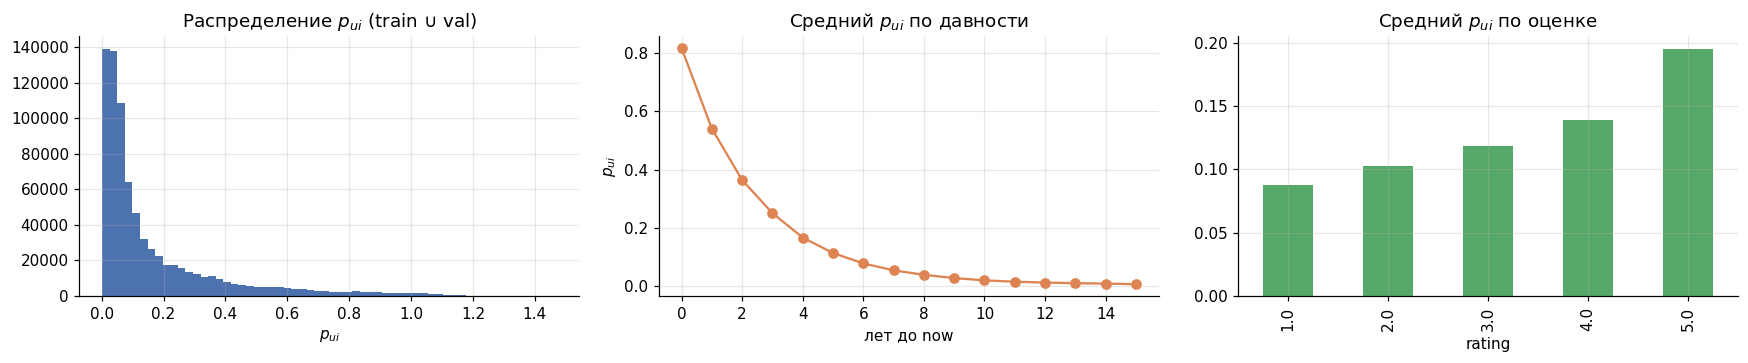

{'factors': 256, 'reg': 137.586, 'alpha': 53.59, 'beta': 0.84, 'half_life_days': 625.958, 'floor': 0.007}


In [22]:
target = custom_target(test_split.train, bp["beta"], bp["half_life_days"], bp["floor"])
age_years = (test_split.train.now - test_split.train.interactions.ts.to_numpy()) / 86400 / 365
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].hist(target, bins=60, color="#4C72B0"); ax[0].set(title="Распределение $p_{ui}$ (train ∪ val)", xlabel="$p_{ui}$")
pd.Series(target).groupby(np.minimum(age_years, 15).astype(int)).mean().plot(ax=ax[1], marker="o", color="#DD8452")
ax[1].set(title="Средний $p_{ui}$ по давности", xlabel="лет до now", ylabel="$p_{ui}$")
pd.Series(target).groupby(test_split.train.interactions.rating.to_numpy()).mean().plot.bar(ax=ax[2], color="#55A868")
ax[2].set(title="Средний $p_{ui}$ по оценке", xlabel="rating")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in bp.items()})

0.0184 против 0.0124 у iALS, весь прирост от давности.

### 7.2 Влияние метаданных в FM

In [23]:
ids = ("user_id", "item_id")
static_meta = tuple(f for f in USER_FIELDS + ITEM_FIELDS if f not in ids)
context = USER_CONTEXT_FIELDS + ITEM_CONTEXT_FIELDS
fm_variants = {
    "только ID": ids,
    "ID + статические метаданные": ids + static_meta,
    "ID + контекст": ids + context,
    "все признаки": ALL_FIELDS,
    "без ID": static_meta + context,
}
print("подобранный набор полей FM:", fm_fields(best_params["FM"]))
rows, fm_per_user = [], {}
for name, fields in fm_variants.items():
    row = {"вариант": name}
    for split in (val_split, test_split):
        model = make_fm(best_params["FM"], fields=fields)
        res, _ = fit_evaluate(model, split, K)
        row[f"NDCG@10 {split.name}"], row[f"Recall@10 {split.name}"] = res.metrics["ndcg"], res.metrics["recall"]
        row[f"Coverage@10 {split.name}"] = res.metrics["coverage"]
        if split is test_split:
            fm_per_user[name] = res.per_user
            row["признаков"] = len(model.feature_names)
        del model
    rows.append(row)
fm_table = pd.DataFrame(rows).set_index("вариант")
display(fm_table)
display(pd.DataFrame({
    f"все признаки − {b}": paired_bootstrap_diff(fm_per_user["все признаки"]["ndcg"], fm_per_user[b]["ndcg"], seed=SEED)
    for b in ("только ID", "ID + статические метаданные", "ID + контекст", "без ID")
}).T.rename(columns={"diff": "ΔNDCG@10 test", "ci_low": "ДИ 2.5%", "ci_high": "ДИ 97.5%", "p_le_0": "P(Δ ≤ 0)"}))

подобранный набор полей FM: ('user_id', 'u_cat', 'u_last_cat', 'u_store', 'i_cat', 'i_store', 'i_main_cat', 'i_title', 'i_rated', 'c_user_activity', 'c_user_recency', 'c_item_age', 'c_item_pop', 'c_item_pop_recent')


,NDCG@10 validation,Recall@10 validation,Coverage@10 validation,NDCG@10 test,Recall@10 test,Coverage@10 test,признаков
вариант,,,,,,,
только ID,0.0092,0.0167,0.1143,0.0100,0.0170,0.1081,120374
ID + статические метаданные,0.0088,0.0152,0.1307,0.0084,0.0141,0.1410,124642
ID + контекст,0.0214,0.0381,0.0075,0.0172,0.0304,0.0087,120428
все признаки,0.0261,0.0466,0.0681,0.0236,0.0393,0.0713,124696
без ID,0.0294,0.0536,0.0852,0.0224,0.0394,0.0891,4322


,ΔNDCG@10 test,ДИ 2.5%,ДИ 97.5%,P(Δ ≤ 0)
все признаки − только ID,0.0137,0.0108,0.0166,0.0000
все признаки − ID + статические метаданные,0.0152,0.0126,0.0179,0.0000
все признаки − ID + контекст,0.0064,0.0039,0.0092,0.0000
все признаки − без ID,0.0012,-0.0010,0.0035,0.1520


Метаданные помогают только вместе с временными признаками, `item_id` лишний.

### 7.3 Качество по сегментам активности пользователей (test)

,Popular,ItemKNN,EASE,iALS,iALS-custom,FM,пользователей
1–4,0.0159,0.0143,0.0121,0.0139,0.0174,0.0214,3027
5–9,0.0161,0.0135,0.0119,0.0114,0.0179,0.0254,2272
10–19,0.0142,0.0138,0.0131,0.0113,0.0218,0.0244,890
20+,0.0163,0.0222,0.0114,0.0084,0.0221,0.0346,357


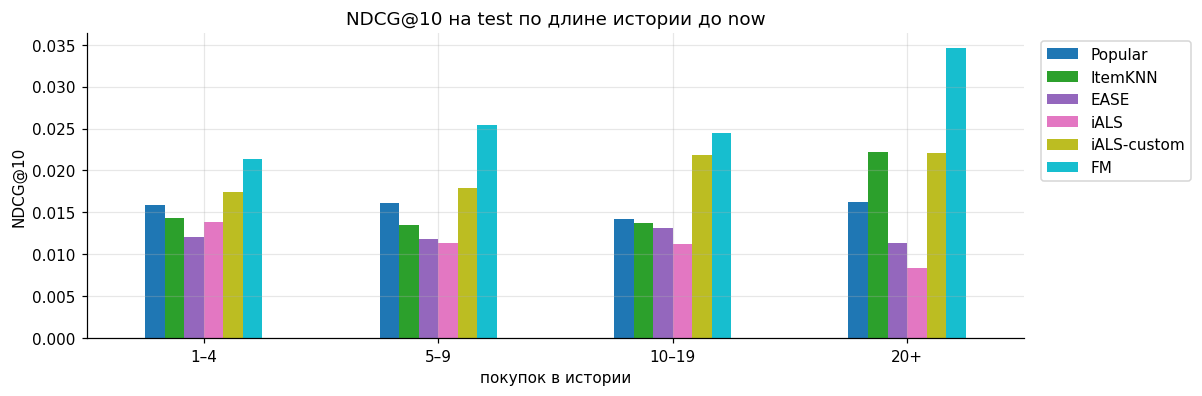

In [24]:
hist_len = pd.Series(np.asarray(test_split.history.getnnz(axis=1))[test_split.users], index=test_split.users)
bucket = pd.cut(hist_len, [0, 4, 9, 19, np.inf], labels=["1–4", "5–9", "10–19", "20+"])
seg = pd.DataFrame({name: test_results[name].per_user["ndcg"].groupby(bucket, observed=True).mean() for name in MODEL_ORDER})
seg["пользователей"] = bucket.value_counts().reindex(seg.index)
display(seg)
seg[MODEL_ORDER].plot.bar(figsize=(11, 3.6), colormap="tab10", rot=0)
plt.title("NDCG@10 на test по длине истории до now"); plt.xlabel("покупок в истории"); plt.ylabel("NDCG@10")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()

### 7.4 Точность против разнообразия

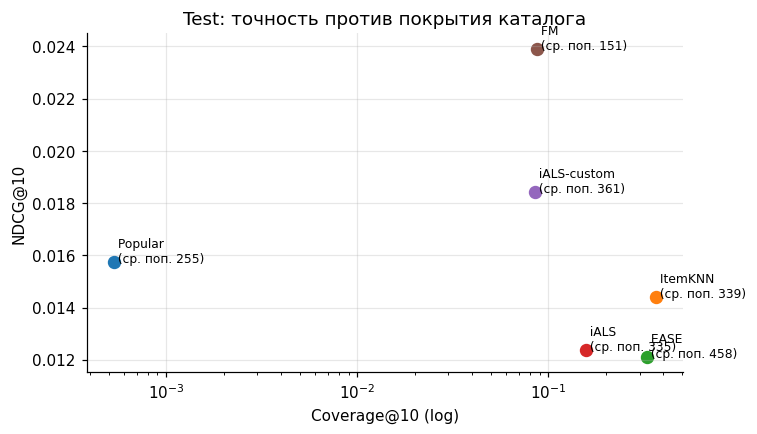

,Popular,ItemKNN,EASE,iALS,iALS-custom,FM
Popular,1.00,0.02,0.02,0.02,0.03,0.15
ItemKNN,0.02,1.00,0.40,0.28,0.33,0.04
EASE,0.02,0.40,1.00,0.39,0.23,0.04
iALS,0.02,0.28,0.39,1.00,0.24,0.05
iALS-custom,0.03,0.33,0.23,0.24,1.00,0.07
FM,0.15,0.04,0.04,0.05,0.07,1.00


полное время выполнения ноутбука: 93.0 мин


In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
for name in MODEL_ORDER:
    m = test_results[name].metrics
    ax.scatter(m["coverage"], m["ndcg"], s=60)
    ax.annotate(f" {name}\n (ср. поп. {m['mean_rec_popularity']:.0f})", (m["coverage"], m["ndcg"]), fontsize=8)
ax.set(xscale="log", xlabel="Coverage@10 (log)", ylabel="NDCG@10", title="Test: точность против покрытия каталога")
plt.show()

overlap = pd.DataFrame(index=MODEL_ORDER, columns=MODEL_ORDER, dtype=float)
for a in MODEL_ORDER:
    for b in MODEL_ORDER:
        ta, tb = test_results[a].top, test_results[b].top
        overlap.loc[a, b] = np.mean([len(set(x) & set(y)) / K for x, y in zip(ta, tb)])
display(overlap.style.format("{:.2f}").background_gradient(cmap="Blues").set_caption("Среднее пересечение top-10 списков"))
print(f"полное время выполнения ноутбука: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} мин")

## 8. Выводы и ограничения

### Выводы

Лучше всего FM с метаданными и временным контекстом (NDCG@10 0.0239 против 0.0157 у Popular). Модели без учёта времени проигрывают даже Popular.

### Ограничения эксперимента

Фильтр по 5 отзывам считался по всем данным, отзыв не равен покупке, холодный старт не оценивался, разбиение по времени одно.